# Step 2: Exploratory Data Analysis (EDA)
### Why are orders late, and which orders lose money?

In Step 1 I cleaned the data and learned that "late" simply means *real shipping days > promised days*.
In this step I try to find **what actually drives late delivery**, using only information known when the order is placed.

Instead of drawing every possible chart, I ask specific questions:

1. How often are orders late, and by how much?
2. Does the **shipping mode** matter?
3. Does **where** the order goes, **who** the customer is, or **what** they buy matter?
4. Does the **time** the order is placed matter?
5. Is the late rate changing over the years?
6. Which orders **lose money**, and is that connected to late delivery?

For each question I show a chart and, where useful, a **statistical test**, then write down what I learned in plain words.

## 1. Setup and load the cleaned data

In [1]:
import sys, os, subprocess
IN_COLAB = "google.colab" in sys.modules

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency, mannwhitneyu

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
LATE_COLOR, ONTIME_COLOR, NEUTRAL = "#DD8452", "#4C72B0", "#8C8C8C"
pct = plt.FuncFormatter(lambda y, _: f"{y:.0%}")

This cell loads the cleaned files from Step 1. If they're not found (for example, a fresh Colab session), it downloads the raw data again and repeats the Step 1 cleaning, so this notebook always works on its own.

In [2]:
def find_processed_dir():
    candidates = ["/content/drive/MyDrive/dataco-final-project/processed",
                  "/content/dataco-final-project/processed",
                  os.path.join("..", "data", "processed")]
    if IN_COLAB:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive not mounted:", e)
    for c in candidates:
        if os.path.exists(os.path.join(c, "orders_clean.parquet")):
            return c
    return None

def rebuild_from_raw():
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    data_dir = kagglehub.dataset_download("shashwatwork/dataco-smart-supply-chain-for-big-data-analysis")
    raw = pd.read_csv(os.path.join(data_dir, "DataCoSupplyChainDataset.csv"), encoding="latin-1")
    rename = {"Type": "payment_type", "Days for shipping (real)": "days_real",
              "Days for shipment (scheduled)": "days_scheduled", "Benefit per order": "profit",
              "Delivery Status": "delivery_status", "Late_delivery_risk": "late",
              "Category Name": "category", "Customer Id": "customer_id",
              "Customer Segment": "customer_segment", "Department Name": "department",
              "Market": "market", "Order Country": "order_country", "order date (DateOrders)": "order_date",
              "Order Id": "order_id", "Order Item Discount": "discount", "Order Item Discount Rate": "discount_rate",
              "Order Item Id": "item_id", "Order Item Profit Ratio": "profit_ratio", "Order Item Quantity": "quantity",
              "Sales": "gross_sales", "Order Item Total": "net_sales", "Order Region": "order_region",
              "Order Status": "order_status", "Product Name": "product", "Product Price": "price",
              "Shipping Mode": "shipping_mode"}
    df = raw[list(rename)].rename(columns=rename)
    df["order_date"] = pd.to_datetime(df["order_date"])
    df["is_canceled"] = df["delivery_status"].eq("Shipping canceled")
    df["delay_gap"] = df["days_real"] - df["days_scheduled"]
    orders = (df.groupby("order_id")
                .agg(order_date=("order_date", "first"), customer_segment=("customer_segment", "first"),
                     market=("market", "first"), order_region=("order_region", "first"),
                     order_country=("order_country", "first"), shipping_mode=("shipping_mode", "first"),
                     payment_type=("payment_type", "first"), days_scheduled=("days_scheduled", "first"),
                     days_real=("days_real", "first"), late=("late", "first"), is_canceled=("is_canceled", "first"),
                     gross_sales=("gross_sales", "sum"), net_sales=("net_sales", "sum"),
                     total_discount=("discount", "sum"), profit=("profit", "sum"))
                .reset_index())
    orders["avg_discount_rate"] = orders["total_discount"] / orders["gross_sales"]
    orders["profit_margin"] = orders["profit"] / orders["net_sales"]
    orders["delay_gap"] = orders["days_real"] - orders["days_scheduled"]
    return df, orders

proc = find_processed_dir()
if proc:
    items = pd.read_parquet(os.path.join(proc, "items_clean.parquet"))
    orders = pd.read_parquet(os.path.join(proc, "orders_clean.parquet"))
    print("Loaded cleaned files from:", proc)
else:
    print("Cleaned files not found - rebuilding from raw data (about 1 minute)...")
    items, orders = rebuild_from_raw()

# Delivery questions only make sense for orders that actually shipped
ship_orders = orders[~orders["is_canceled"]].copy()
ship_items = items[~items["is_canceled"]].copy()
ship_orders["order_hour"] = ship_orders["order_date"].dt.hour
ship_orders["order_weekday"] = ship_orders["order_date"].dt.day_name()
ship_orders["order_month"] = ship_orders["order_date"].dt.month
ship_orders["order_year"] = ship_orders["order_date"].dt.year

print(f"Shipped orders: {len(ship_orders):,}   Shipped order items: {len(ship_items):,}")

Loaded cleaned files from: ..\data\processed
Shipped orders: 62,897   Shipped order items: 172,765


### A small helper for statistical tests
With about 63,000 orders, even a tiny difference can come out "statistically significant". So for every comparison I report two things:
- **p-value (chi-square test):** is the difference likely to be real, or just random noise? (p < 0.05 = probably real)
- **Cramér's V (effect size):** how *strong* is the relationship? 0 = none, 0.1 = weak, 0.3 = moderate, 0.5+ = strong.

In [3]:
def association(df, col, target="late"):
    table = pd.crosstab(df[col], df[target])
    rates = df.groupby(col)[target].mean()
    if min(table.shape) < 2:   # e.g. every order in the group is late -> nothing to test
        return {"feature": col, "p_value": 1.0, "cramers_v": 0.0,
                "lowest_rate": rates.min(), "highest_rate": rates.max()}
    chi2, p, _, _ = chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    return {"feature": col, "p_value": p, "cramers_v": v,
            "lowest_rate": rates.min(), "highest_rate": rates.max()}

def strength(v):
    return "none" if v < 0.05 else "weak" if v < 0.1 else "moderate" if v < 0.3 else "strong"

## Q1. How often are orders late, and by how much?

Share of shipped orders delivered late: 57.3%


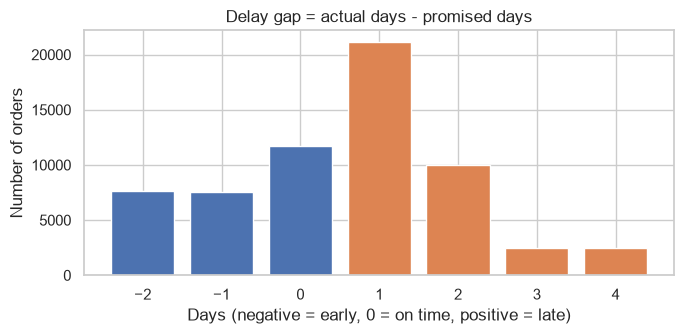

In [4]:
overall_late = ship_orders["late"].mean()
print(f"Share of shipped orders delivered late: {overall_late:.1%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
gap_counts = ship_orders["delay_gap"].value_counts().sort_index()
colors = [LATE_COLOR if g > 0 else ONTIME_COLOR for g in gap_counts.index]
ax.bar(gap_counts.index, gap_counts.values, color=colors)
ax.set_title("Delay gap = actual days - promised days")
ax.set_xlabel("Days (negative = early, 0 = on time, positive = late)")
ax.set_ylabel("Number of orders")
plt.tight_layout(); plt.show()

**What I learned:** about **57% of shipped orders arrive late**. Most late orders are only **1–2 days** late, and the worst case is 4 days.
So the problem is **frequent but small delays**, not rare disasters.

## Q2. Does the shipping mode matter?

,promised_days,avg_actual_days,late_rate,orders
shipping_mode,,,,
Same Day,0,0.48,0.48,3407
First Class,1,2.00,1.00,9602
Second Class,2,4.00,0.80,12256
Standard Class,4,3.99,0.40,37632


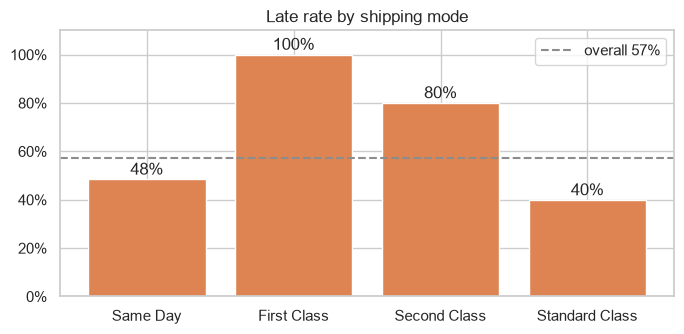

In [5]:
mode_order = ["Same Day", "First Class", "Second Class", "Standard Class"]
mode_stats = (ship_orders.groupby("shipping_mode")
              .agg(promised_days=("days_scheduled", "first"),
                   avg_actual_days=("days_real", "mean"),
                   late_rate=("late", "mean"),
                   orders=("order_id", "count"))
              .reindex(mode_order))
display(mode_stats.round(2))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(mode_stats.index, mode_stats["late_rate"], color=LATE_COLOR)
ax.axhline(overall_late, ls="--", color=NEUTRAL, label=f"overall {overall_late:.0%}")
for i, v in enumerate(mode_stats["late_rate"]):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center")
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1.1)
ax.set_title("Late rate by shipping mode"); ax.legend()
plt.tight_layout(); plt.show()

### Promised days vs actual days
This heatmap is the most important chart in this step. Each row is a shipping mode, each column is how many days the order *actually* took.

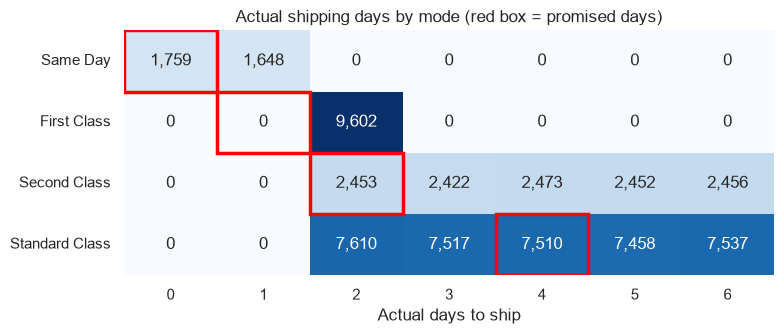

{'feature': 'shipping_mode', 'p_value': np.float64(0.0), 'cramers_v': np.float64(0.4806501686099911), 'lowest_rate': np.float64(0.3984640731292517), 'highest_rate': np.float64(1.0)}


In [6]:
promise_vs_actual = pd.crosstab(ship_orders["shipping_mode"], ship_orders["days_real"]).reindex(mode_order)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.heatmap(promise_vs_actual, annot=True, fmt=",", cmap="Blues", cbar=False, ax=ax)
for i, mode in enumerate(mode_order):
    promised = mode_stats.loc[mode, "promised_days"]
    ax.add_patch(plt.Rectangle((promised, i), 1, 1, fill=False, edgecolor="red", lw=2.5))
ax.set_title("Actual shipping days by mode (red box = promised days)")
ax.set_xlabel("Actual days to ship"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

print(association(ship_orders, "shipping_mode"))

**What I learned (this is the main insight):**
- **First Class always takes exactly 2 days**, but promises 1. So **100% of First Class orders are late**.
- **Second Class and Standard Class take the same time**: anywhere from 2 to 6 days, spread evenly.
  Second Class promises 2 days, so it's late about 80% of the time. Standard promises 4 days, so it's late only about 40% of the time.
- Paying for Second Class over Standard **doesn't make the package arrive faster**. It only makes the promise tighter.
- Shipping mode has a **strong** relationship with lateness (Cramér's V ≈ 0.48).

**Business meaning:** the delivery operation isn't failing randomly. **The promises for the premium modes are unrealistic.**

## Q3. Do *where*, *who* or *what* matter?
Many people assume late delivery depends on the region, the customer type or the product. Let me test that.

In [7]:
order_level_features = ["market", "order_region", "customer_segment", "payment_type",
                        "order_weekday", "order_month", "order_year"]
results = [association(ship_orders, c) for c in order_level_features]
results += [association(ship_items, c) for c in ["category", "department"]]  # product info is per item
assoc = pd.DataFrame(results)
assoc["significant (p<0.05)"] = assoc["p_value"] < 0.05
assoc["strength"] = assoc["cramers_v"].apply(strength)
assoc.round(4)

,feature,p_value,cramers_v,lowest_rate,highest_rate,significant (p<0.05),strength
0,market,0.5289,0.0071,0.5655,0.5768,False,none
1,order_region,0.1031,0.0221,0.5258,0.6004,False,none
2,customer_segment,0.5882,0.0041,0.5716,0.5774,False,none
3,payment_type,0.6958,0.0048,0.5673,0.5748,False,none
4,order_weekday,0.9461,0.0052,0.5690,0.5764,False,none
5,order_month,0.7619,0.0109,0.5611,0.5787,False,none
6,order_year,0.3741,0.0070,0.5703,0.5866,False,none
7,category,0.5811,0.0164,0.4927,0.6885,False,none
8,department,0.7380,0.0063,0.5677,0.6144,False,none


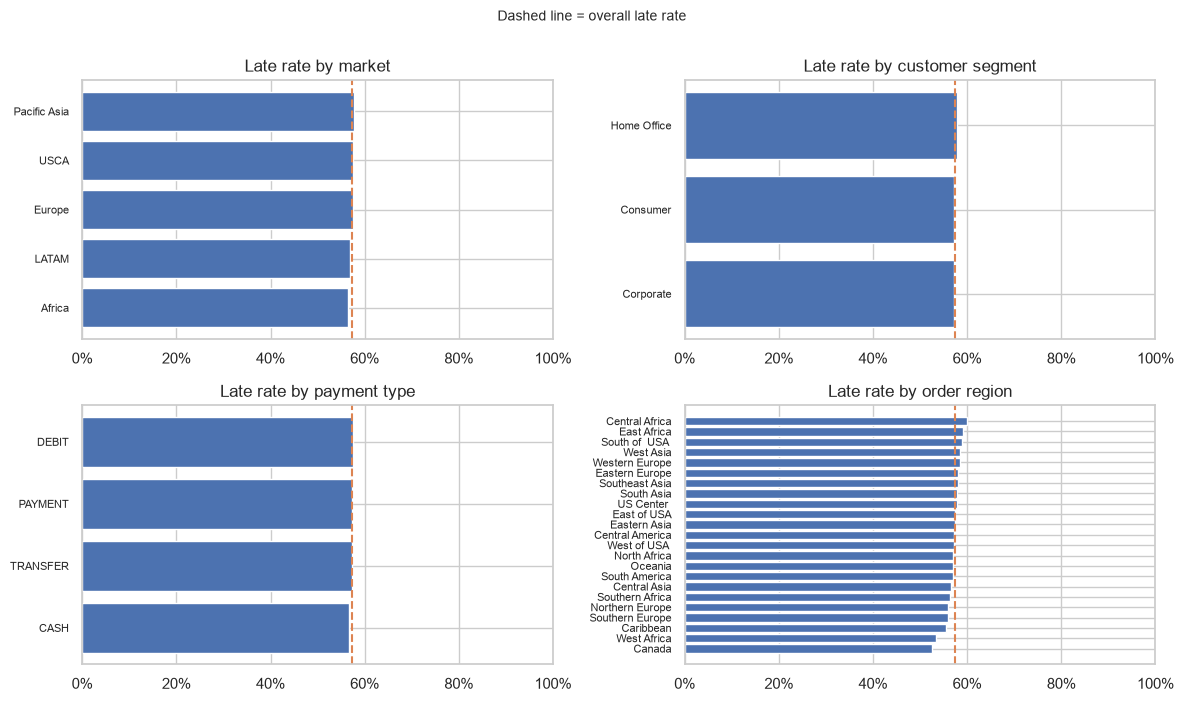

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col, data in [(axes[0, 0], "market", ship_orders), (axes[0, 1], "customer_segment", ship_orders),
                      (axes[1, 0], "payment_type", ship_orders), (axes[1, 1], "order_region", ship_orders)]:
    rates = data.groupby(col)["late"].mean().sort_values()
    ax.barh(rates.index, rates.values, color=ONTIME_COLOR)
    ax.axvline(overall_late, ls="--", color=LATE_COLOR)
    ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(pct)
    ax.set_title(f"Late rate by {col.replace('_', ' ')}")
    ax.tick_params(axis="y", labelsize=8)
plt.suptitle("Dashed line = overall late rate", y=1.0, fontsize=10)
plt.tight_layout(); plt.show()

**What I learned:** the bars are almost all the same length.
**Market, region, customer segment, payment type, weekday, month, year, product category and department have no meaningful effect on late delivery.**
The p-values are mostly above 0.05, and every Cramér's V is close to 0.

This surprised me, and it is an important result for the modelling step: the models won't find much signal in these columns.

### Double-check: maybe region matters *within* the same shipping mode?
Different regions might use different shipping modes, which could hide a regional effect. So I look only at **Standard Class** orders.

In [9]:
standard = ship_orders[ship_orders["shipping_mode"] == "Standard Class"]
within = pd.DataFrame([association(standard, c) for c in ["market", "order_region", "customer_segment", "payment_type"]])
within["strength"] = within["cramers_v"].apply(strength)
within.round(4)

,feature,p_value,cramers_v,lowest_rate,highest_rate,strength
0,market,0.6940,0.0077,0.3934,0.4035,none
1,order_region,0.2012,0.0269,0.3295,0.4434,none
2,customer_segment,0.1268,0.0105,0.3911,0.4050,none
3,payment_type,0.4975,0.0080,0.3877,0.4001,none


**What I learned:** even within Standard Class, region and customer type still make **no real difference**. The result holds.

## Q4. Does the time of day matter?

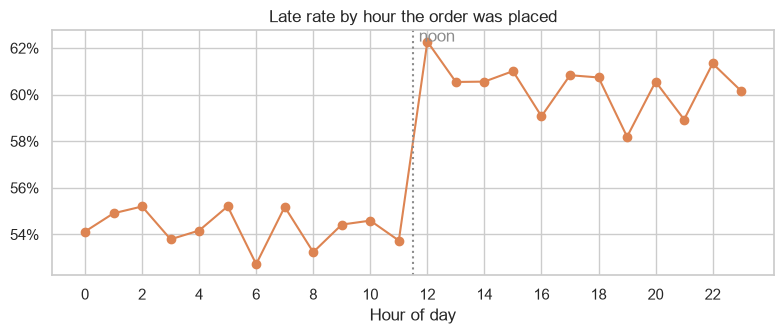

{'feature': 'order_hour', 'p_value': np.float64(6.323279500547561e-42), 'cramers_v': np.float64(0.06423096267495003), 'lowest_rate': np.float64(0.5272588638963019), 'highest_rate': np.float64(0.6227867590454196)}


In [10]:
hourly = ship_orders.groupby("order_hour")["late"].mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(hourly.index, hourly.values, marker="o", color=LATE_COLOR)
ax.axvline(11.5, ls=":", color=NEUTRAL); ax.text(11.7, hourly.max(), "noon", color=NEUTRAL)
ax.yaxis.set_major_formatter(pct); ax.set_xticks(range(0, 24, 2))
ax.set_title("Late rate by hour the order was placed"); ax.set_xlabel("Hour of day")
plt.tight_layout(); plt.show()
print(association(ship_orders, "order_hour"))

There is a visible **jump at noon**: orders placed after 12:00 are late more often. Which shipping mode causes this?

In [11]:
for mode in mode_order:
    sub = ship_orders[ship_orders["shipping_mode"] == mode]
    r = association(sub, "order_hour")
    print(f"{mode:15s} p-value = {r['p_value']:.4f}   Cramer's V = {r['cramers_v']:.3f}")

same_day = ship_orders[ship_orders["shipping_mode"] == "Same Day"].copy()
same_day["placed"] = np.where(same_day["order_hour"] < 12, "Before noon", "After noon")
pd.crosstab(same_day["placed"], same_day["days_real"], margins=True).rename(
    columns={0: "shipped same day (0 days)", 1: "took 1 day"})

Same Day        p-value = 0.0000   Cramer's V = 1.000
First Class     p-value = 1.0000   Cramer's V = 0.000
Second Class    p-value = 0.9744   Cramer's V = 0.031
Standard Class  p-value = 0.8636   Cramer's V = 0.020


days_real,shipped same day (0 days),took 1 day,All
placed,,,
After noon,0,1648,1648
Before noon,1759,0,1759
All,1759,1648,3407


**What I learned (a hidden business rule):** the noon effect comes **only from Same Day orders**, and it's perfect:
- Same Day orders placed **before noon** always ship the same day, so they are **on time**.
- Same Day orders placed **after noon** always take 1 day, so they are **late**.

There's a **12:00 cut-off** for same-day shipping that the customer isn't told about.
**Recommendation:** either tell customers about the cut-off, or only offer "Same Day" before noon.

## Q5. Is the late rate changing over time?

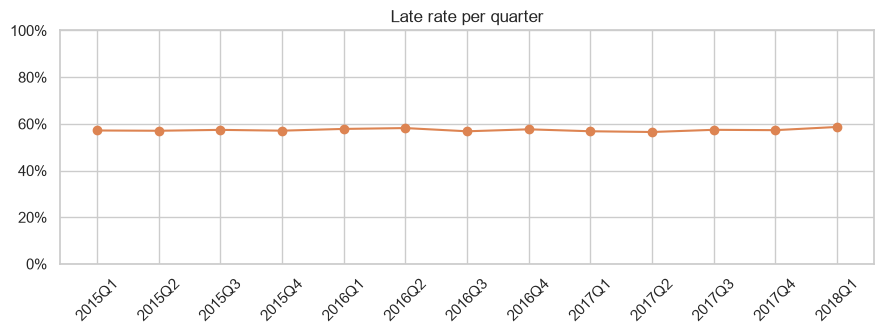

order_date,2015Q1,2015Q2,2015Q3,2015Q4,2016Q1,2016Q2,2016Q3,2016Q4,2017Q1,2017Q2,2017Q3,2017Q4,2018Q1
mean,0.572,0.57,0.574,0.571,0.578,0.582,0.568,0.577,0.568,0.565,0.574,0.573,0.587
count,4920.000,4974.00,5016.000,5085.000,4977.000,4922.000,5024.000,5032.000,4933.000,4943.000,5028.000,6006.000,2037.000


In [12]:
quarterly = ship_orders.groupby(ship_orders["order_date"].dt.to_period("Q"))["late"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(quarterly.index.astype(str), quarterly["mean"], marker="o", color=LATE_COLOR)
ax.set_ylim(0, 1); ax.yaxis.set_major_formatter(pct)
ax.set_title("Late rate per quarter"); ax.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
quarterly.round(3).T

**What I learned:** the late rate stays at **about 57% every quarter** for three years. The company never improved, which suggests nobody noticed the promise problem.
It also means a model trained on older orders should still work on newer orders. That supports my time-based train/test split.

## Q6. Which orders lose money?
The second business question in my proposal: some orders have a **negative profit**. Who are they, and is it because of late delivery?

In [13]:
loss_orders = ship_orders["profit"] < 0
gross_profit = ship_items.loc[ship_items["profit"] > 0, "profit"].sum()
total_losses = ship_items.loc[ship_items["profit"] < 0, "profit"].sum()
print(f"Orders with a loss:              {loss_orders.mean():.1%}")
print(f"Profit from profitable items:    ${gross_profit:,.0f}")
print(f"Money lost on loss-making items: ${total_losses:,.0f}")
print(f"-> losses cancel out {abs(total_losses) / gross_profit:.0%} of the profit")

Orders with a loss:              21.1%
Profit from profitable items:    $7,514,814
Money lost on loss-making items: $-3,708,393
-> losses cancel out 49% of the profit


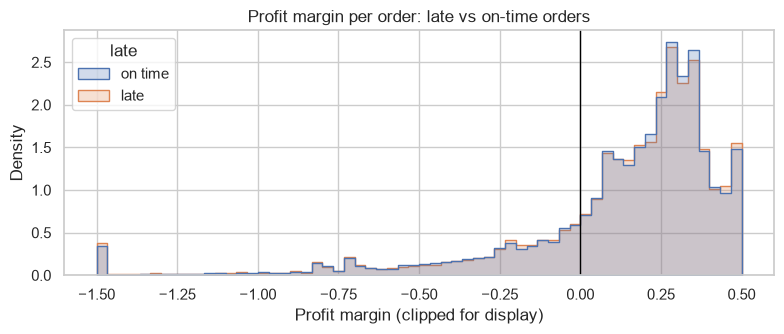

Loss rate - on time: 0.209 | late: 0.213
Chi-square (late vs loss): {'feature': 'late', 'p_value': np.float64(0.2446930861379637), 'cramers_v': np.float64(0.004638636184029025), 'lowest_rate': np.float64(0.20913255614734255), 'highest_rate': np.float64(0.21299378606302707)}
Mann-Whitney test on profit margin: p = 0.638


In [14]:
fig, ax = plt.subplots(figsize=(8, 3.5))
clip = ship_orders["profit_margin"].clip(-1.5, 0.6)
sns.histplot(x=clip, hue=ship_orders["late"].map({0: "on time", 1: "late"}), bins=60,
             stat="density", common_norm=False, element="step", ax=ax,
             palette={"on time": ONTIME_COLOR, "late": LATE_COLOR})
ax.axvline(0, color="black", lw=1)
ax.set_title("Profit margin per order: late vs on-time orders"); ax.set_xlabel("Profit margin (clipped for display)")
plt.tight_layout(); plt.show()

ship_orders["loss"] = loss_orders.astype(int)
print("Loss rate - on time:", round(ship_orders.loc[ship_orders.late == 0, "loss"].mean(), 3),
      "| late:", round(ship_orders.loc[ship_orders.late == 1, "loss"].mean(), 3))
print("Chi-square (late vs loss):", association(ship_orders, "late", target="loss"))
mw = mannwhitneyu(ship_orders.loc[ship_orders.late == 1, "profit_margin"],
                  ship_orders.loc[ship_orders.late == 0, "profit_margin"])
print(f"Mann-Whitney test on profit margin: p = {mw.pvalue:.3f}")

**What I learned:** about **1 in 5 orders loses money**, and those losses cancel out roughly **half of all profit**. That's a big problem.
But late and on-time orders have **the same** loss rate and the same profit-margin shape (both tests: p > 0.05).
**Late delivery is not what makes orders lose money.**

So what does? Let me check discounts, products and markets.

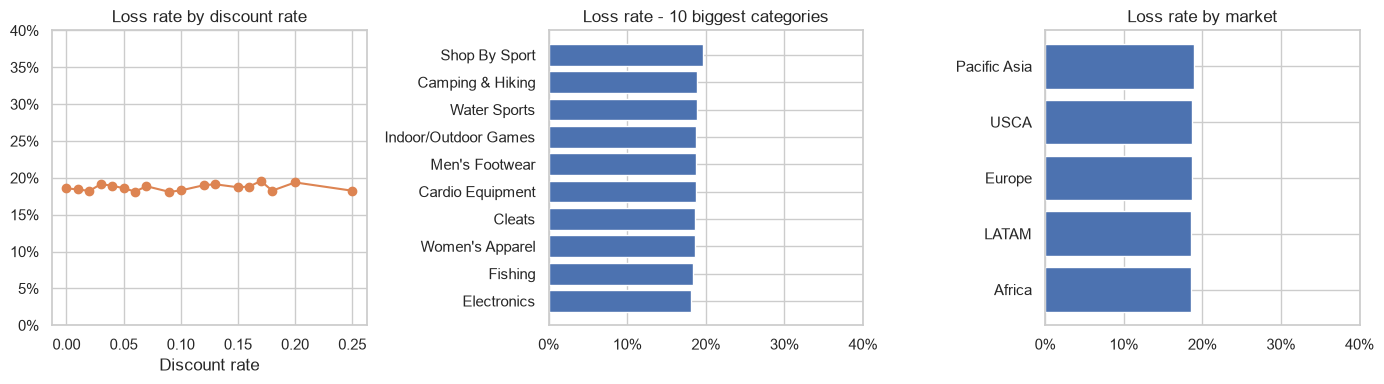

,feature,p_value,cramers_v,lowest_rate,highest_rate
0,discount_rate,0.2120,0.0111,0.1810,0.1959
1,category,0.1766,0.0183,0.0984,0.2424
2,market,0.8070,0.0031,0.1859,0.1891
3,shipping_mode,0.0980,0.0060,0.1823,0.1893
4,customer_segment,0.6169,0.0024,0.1861,0.1881


In [15]:
ship_items["loss"] = (ship_items["profit"] < 0).astype(int)
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

by_disc = ship_items.groupby("discount_rate")["loss"].mean()
axes[0].plot(by_disc.index, by_disc.values, marker="o", color=LATE_COLOR)
axes[0].set_title("Loss rate by discount rate"); axes[0].set_xlabel("Discount rate")

top_cats = ship_items["category"].value_counts().head(10).index
by_cat = ship_items[ship_items["category"].isin(top_cats)].groupby("category")["loss"].mean().sort_values()
axes[1].barh(by_cat.index, by_cat.values, color=ONTIME_COLOR)
axes[1].set_title("Loss rate - 10 biggest categories")

by_mkt = ship_items.groupby("market")["loss"].mean().sort_values()
axes[2].barh(by_mkt.index, by_mkt.values, color=ONTIME_COLOR)
axes[2].set_title("Loss rate by market")

for ax in axes:
    (ax.yaxis if ax is axes[0] else ax.xaxis).set_major_formatter(pct)
    (ax.set_ylim if ax is axes[0] else ax.set_xlim)(0, 0.4)
plt.tight_layout(); plt.show()

pd.DataFrame([association(ship_items, c, target="loss") for c in
              ["discount_rate", "category", "market", "shipping_mode", "customer_segment"]]).round(4)

**What I learned:** the loss rate is about **19% everywhere**: at every discount level, in every big category, in every market.
Losses aren't explained by discount, product, market, shipping mode or customer type.

**Honest interpretation:** the loss information in this dataset looks almost **random** with respect to the order details.
This is likely because the dataset is partly **simulated** (it was built for teaching and research).
I'll mention this as a limitation, and I won't try to build a model for profit, since there's no signal to learn.

## Q7. How do the numeric columns relate to each other?

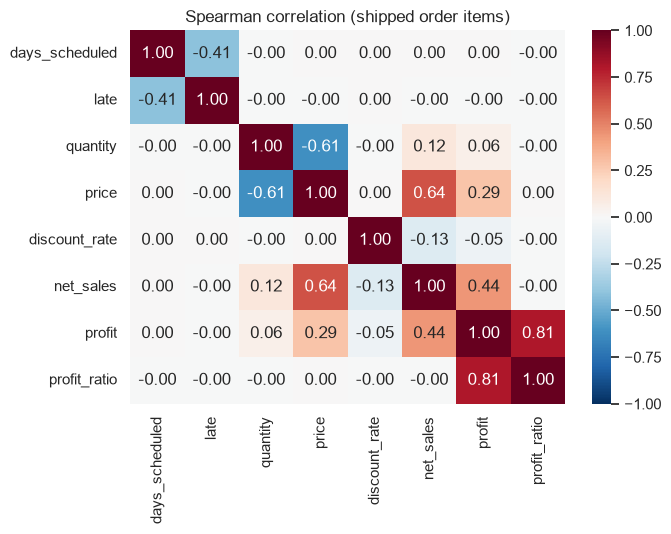

In [16]:
num_cols = ["days_scheduled", "late", "quantity", "price", "discount_rate", "net_sales", "profit", "profit_ratio"]
corr = ship_items[num_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlation (shipped order items)")
plt.tight_layout(); plt.show()

**What I learned:** the only numeric column clearly related to `late` is **days_scheduled** (the promise), with a correlation of about −0.41. Price, quantity, discount and profit have essentially **zero** correlation with late delivery.
`profit` and `profit_ratio` move together, as expected.

## Summary of Step 2

| Question | Answer |
|---|---|
| How often are orders late? | **57%** of shipped orders, mostly by 1–2 days |
| Does shipping mode matter? | **Yes, strongly.** First Class is 100% late (always 2 days vs 1 promised). Second Class takes the same time as Standard but promises less, so it's 80% vs 40% late |
| Do region / market / customer / product / payment matter? | **No.** No meaningful effect, even within the same shipping mode |
| Does time of day matter? | **Only for Same Day**: before noon is always on time, after noon is always late. A hidden **12:00 cut-off** |
| Is it changing over time? | No. About 57% every quarter for 3 years |
| Which orders lose money? | About 1 in 5, cancelling out about half of all profit, but **not linked** to late delivery, discount, product or market |

### What this means for Step 3 (modelling)
- The useful information is **shipping mode** + **order hour** (for Same Day). The other columns add little.
- I can calculate the **best possible accuracy** from the data itself. First Class and Same Day are fully predictable. Second Class is late 80% of the time, so predict "late" and be right 80% of the time. Standard is late 40% of the time, so predict "on time" and be right 60% of the time. That gives a ceiling of about **72% accuracy**.
- If a model scores much higher than that, it's probably **cheating** (data leakage). That's the exact trap the 99%-accuracy notebooks fell into.
- My plan: compare Logistic Regression, Random Forest and XGBoost against this "ceiling", and show which features each model relies on.

### Business recommendations so far
1. **Fix the promises:** First Class should promise 2 days. Second Class currently gives no real speed benefit over Standard.
2. **Publish the noon cut-off** for Same Day shipping.
3. **Investigate the loss-making orders separately.** They're not a delivery problem.